# Trainable blocks — `master_opt-adam_lr-1.0_init-zeros_wov-fixed_ep-1000`, α = 0.6

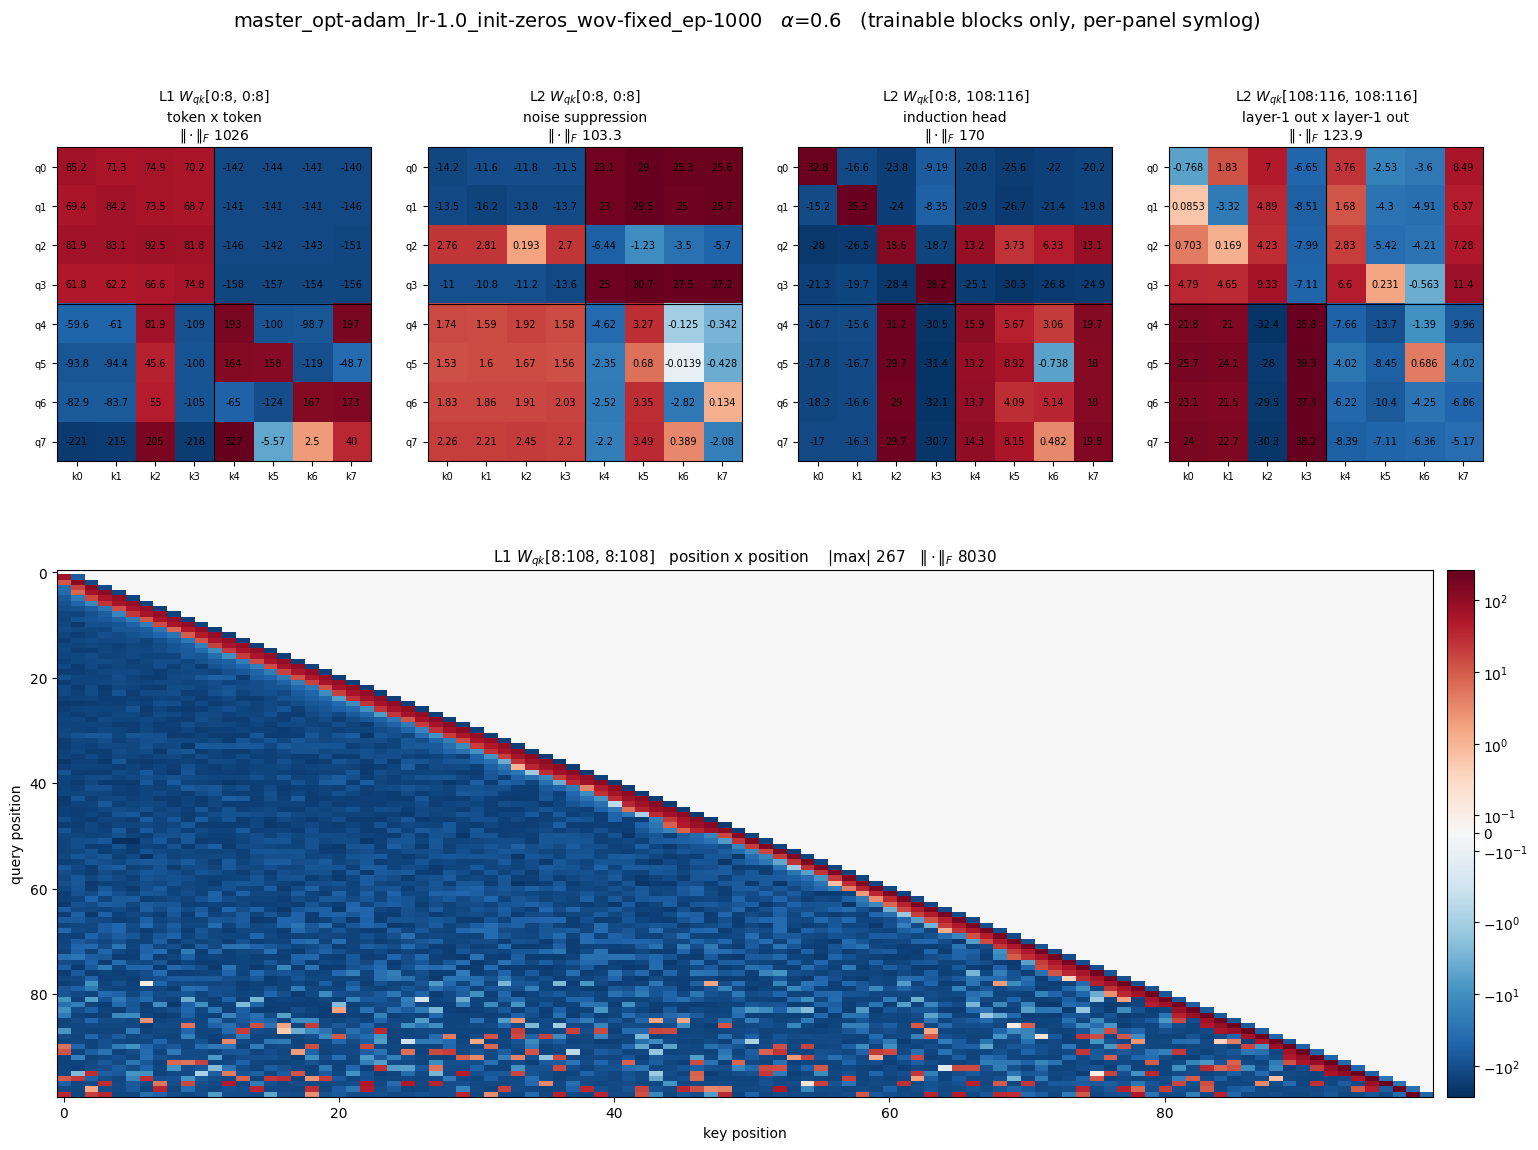

In [2]:
import os, torch, numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import SymLogNorm

RUN = 'master_opt-adam_lr-1.0_init-zeros_wov-fixed_ep-1000'
THR, SEED, V, D1 = 0.6, 0, 8, 108

sd = torch.load(os.path.join('runs', RUN, f'model_final_seed{SEED}_x_{THR}.pth'),
                map_location='cpu', weights_only=True)
g = lambda n, r, c: sd[n].numpy().astype(np.float64)[r, c]

small = [  # the 8x8 blocks, values printed
    ('L1 $W_{qk}$[0:8, 0:8]\ntoken x token',            g('layer1.W_qk', slice(0, V), slice(0, V))),
    ('L2 $W_{qk}$[0:8, 0:8]\nnoise suppression',        g('layer2.W_qk', slice(0, V), slice(0, V))),
    ('L2 $W_{qk}$[0:8, 108:116]\ninduction head',       g('layer2.W_qk', slice(0, V), slice(D1, D1 + V))),
    ('L2 $W_{qk}$[108:116, 108:116]\nlayer-1 out x layer-1 out',
                                                        g('layer2.W_qk', slice(D1, D1 + V), slice(D1, D1 + V))),
]
for nm, blk in (('L1 $W_{ov}$[0:8, 0:8]', g('layer1.W_ov', slice(0, V), slice(0, V))),
                ('L2 $W_{ov}$[0:8, 0:8]', g('layer2.W_ov', slice(0, V), slice(0, V)))):
    if not np.allclose(blk, np.eye(V)):          # skip when frozen to the identity
        small.append((nm + '\ninput selector', blk))

big = ('L1 $W_{qk}$[8:108, 8:108]   position x position',
       g('layer1.W_qk', slice(V, D1), slice(V, D1)))

def norm(A):
    v = float(np.abs(A).max())
    return SymLogNorm(linthresh=max(v / 1e3, 1e-30), linscale=0.6, vmin=-v, vmax=v,
                      base=10) if v > 0 else None

fig = plt.figure(figsize=(4.6 * len(small), 12.5))
gs = fig.add_gridspec(2, len(small), height_ratios=[1, 1.55], hspace=0.22, wspace=0.18)

for j, (title, A) in enumerate(small):
    ax = fig.add_subplot(gs[0, j])
    ax.imshow(A, cmap='RdBu_r', interpolation='nearest', norm=norm(A))
    for i in range(V):
        for k in range(V):
            ax.text(k, i, f'{A[i, k]:.3g}', ha='center', va='center', fontsize=7)
    ax.set_xticks(range(V)); ax.set_yticks(range(V))
    ax.set_xticklabels([f'k{i}' for i in range(V)], fontsize=7)
    ax.set_yticklabels([f'q{i}' for i in range(V)], fontsize=7)
    ax.axhline(3.5, color='k', lw=0.8); ax.axvline(3.5, color='k', lw=0.8)   # signal | noise
    ax.set_title(f'{title}\n$\\|\\cdot\\|_F$ {np.linalg.norm(A):.4g}', fontsize=10)

ax = fig.add_subplot(gs[1, :])
im = ax.imshow(big[1], cmap='RdBu_r', interpolation='nearest', norm=norm(big[1]), aspect='auto')
ax.set_title(f'{big[0]}    |max| {np.abs(big[1]).max():.4g}   '
             f'$\\|\\cdot\\|_F$ {np.linalg.norm(big[1]):.4g}', fontsize=11)
ax.set_xlabel('key position'); ax.set_ylabel('query position')
fig.colorbar(im, ax=ax, fraction=0.025, pad=0.01)

fig.suptitle(f'{RUN}   $\\alpha$={THR}   (trainable blocks only, per-panel symlog)', fontsize=14)
plt.show()